# Pricing engines: identity, convergence and capability

Family 19. QuantLib performs pricing. We compare engines under an identical
constant-coefficient model, then compare separately declared path-dependent and
multi-asset capabilities. All prices are per unit multiplier.

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / 'convexity').exists():
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from convexity.math import contracts as ct, curves as cv, pricing as pr
rng = np.random.default_rng(1900)
ref, expiry = '2026-01-01', '2027-01-01'
discount, dividend = cv.flat_curve(ref, .04), cv.flat_curve(ref, .01)
model = pr.BlackScholesModel(100., discount, dividend, .2)
plt.rcParams.update({'figure.figsize': (9, 3.5), 'figure.dpi': 110,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .2})
print('Interpreter:', sys.executable)

Interpreter: /home/ethan/miniconda3/envs/quant/bin/python


## Put-call parity and quote Greeks

Parity is an independent financial identity. Greeks below hold the model's
other quoted inputs fixed and are per unit change, not per percentage point.

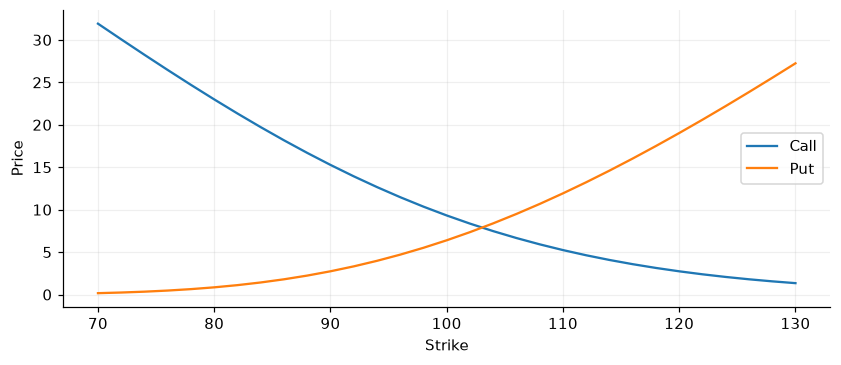

,Strike,Call,Put,Parity residual,Call delta,Call vega
0,70.0,31.914430,0.164708,-3.552714e-15,0.969252,4.997437
5,80.0,22.992909,0.851080,0.000000e+00,0.904892,15.543447
10,90.0,15.275704,2.741770,-8.881784e-15,0.773588,29.210275
15,100.0,9.319738,6.393699,-4.440892e-15,0.592749,38.282070
20,110.0,5.240728,11.922583,2.664535e-15,0.406303,38.496564
25,120.0,2.739030,19.028779,0.000000e+00,0.251583,31.733383
30,130.0,1.344161,27.241805,-7.105427e-15,0.142724,22.477153


In [2]:
from dataclasses import replace
strikes=np.linspace(70,130,31)
rows=[]
for strike in strikes:
    vals=[]
    for kind in ['call','put']:
        contract=ct.VanillaContract(strike,ct.Exercise('european',(expiry,)),kind)
        vals.append(pr.price(pr.PricingProblem(contract,model,ref),pr.VanillaEngine()))
    rows.append((strike,vals[0].value,vals[1].value,vals[0].value-vals[1].value-(100*np.exp(-.01)-strike*np.exp(-.04)),vals[0].greeks['delta'],vals[0].greeks['vega']))
prices=pd.DataFrame(rows,columns=['Strike','Call','Put','Parity residual','Call delta','Call vega'])
prices.plot(x='Strike',y=['Call','Put']);plt.ylabel('Price');plt.show();display(prices.iloc[::5])

## Grid convergence versus Monte Carlo uncertainty

Tree and FD errors are discretization errors. Monte Carlo standard errors
measure sampling variability, not bias. A binomial engine is only admitted here
for constant coefficients; shaped curves require a suitable engine such as FD.

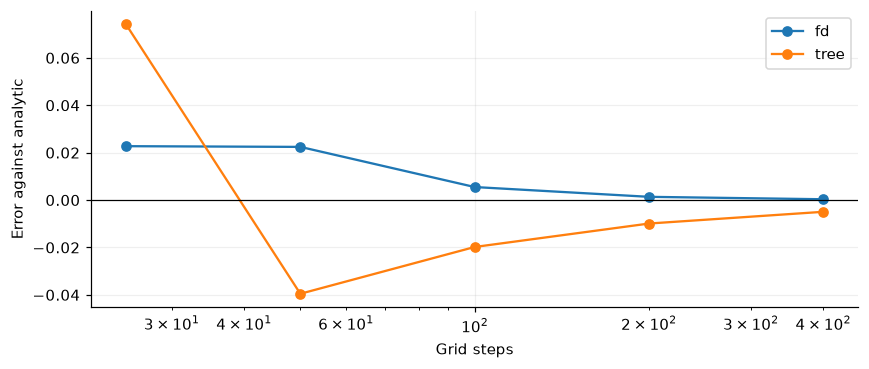

,Draws,MC value,Standard error
0,2000,9.392751,0.320319
1,8000,9.441330,0.157220
2,32000,9.419842,0.078189


In [3]:
contract=ct.VanillaContract(100.,ct.Exercise('european',(expiry,)))
problem=pr.PricingProblem(contract,model,ref)
reference=pr.price(problem,pr.VanillaEngine()).value
rows=[]
for steps in [25,50,100,200,400]:
    for method in ['tree','fd']:
        value=pr.price(problem,pr.VanillaEngine(method,steps=steps,grid=max(50,steps))).value
        rows.append((method,steps,value,value-reference))
convergence=pd.DataFrame(rows,columns=['Engine','Steps','Price','Error'])
for name,data in convergence.groupby('Engine'):
    plt.plot(data.Steps,data.Error,marker='o',label=name)
plt.axhline(0,color='black',lw=.8);plt.xscale('log');plt.xlabel('Grid steps');plt.ylabel('Error against analytic');plt.legend();plt.show()
mc=[]
for n in [2000,8000,32000]:
    result=pr.price(problem,pr.VanillaEngine('mc',steps=2,samples=n,seed=71))
    mc.append((n,result.value,result.error_estimate))
display(pd.DataFrame(mc,columns=['Draws','MC value','Standard error']))

## Heston, averages and correlation

These are distinct claims and models. Basket correlation changes the law of a
weighted sum. Arithmetic and geometric Asian values differ because their payoffs
differ; they are not two estimators of the same price.

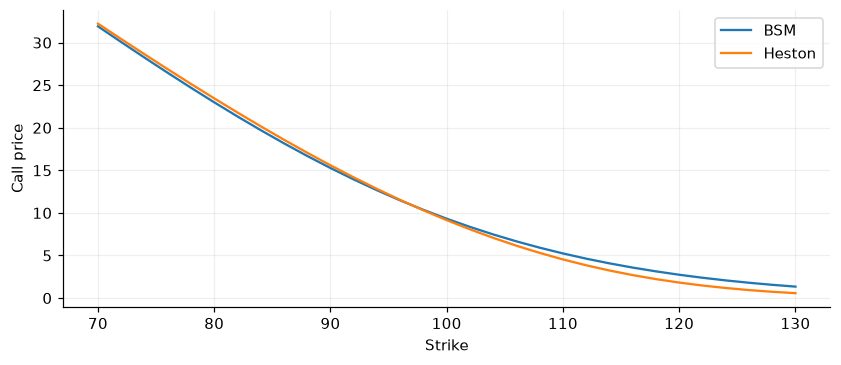

,Claim,Value,Standard error
0,Geometric Asian,6.053950,NaN
1,Arithmetic Asian,6.203053,0.082900
2,Basket correlation -0.5,5.570934,0.066013
3,Basket correlation 0.0,6.952603,0.089703
4,Basket correlation 0.8,8.728093,0.118735


In [4]:
heston=pr.HestonModel(100,discount,dividend,.04,2.,.04,.3,-.7)
values=[pr.price(pr.PricingProblem(ct.VanillaContract(k,ct.Exercise('european',(expiry,))),heston,ref),pr.VanillaEngine('heston')).value for k in strikes]
plt.plot(strikes,prices.Call,label='BSM');plt.plot(strikes,values,label='Heston');plt.xlabel('Strike');plt.ylabel('Call price');plt.legend();plt.show()
fixings=['2026-04-01','2026-07-01','2026-10-01',expiry]
claims=[('Geometric Asian',pr.asian_price(model,ref,100,fixings,average='geometric')),
        ('Arithmetic Asian',pr.asian_price(model,ref,100,fixings,samples=12000))]
for rho in [-.5,0.,.8]:
    claims.append((f'Basket correlation {rho}',pr.basket_price([model,model],[[1,rho],[rho,1]],[.5,.5],ref,expiry,100,samples=12000)))
display(pd.DataFrame([(name,r.value,r.error_estimate) for name,r in claims],columns=['Claim','Value','Standard error']))

## Scope of the evidence

These are generated-data experiments under the stated models, not market forecasts or universal model rankings. Numerical errors, backend restrictions and measure assumptions are documented in the [financial catalog](../financial_mathematics.md) and [QA record](../financial_qa.md). Automated adversarial checks live in `tests/math/finance/`.